# Hito 1 · Recuperación de información científica
## TF-IDF y BM25 sobre artículos de arXiv

**Procesamiento del Lenguaje Natural** · Máster en Inteligencia Artificial Aplicada · UC3M

---

El objetivo de este hito es construir y evaluar dos métodos de búsqueda para un asistente de investigación académica. Partimos de artículos de arXiv y comprobamos si **TF-IDF y BM25 recuperan el artículo buscado entre los primeros resultados**.

**Contenido del notebook**

| Parte | Contenido |
|---|---|
| **1. Corpus** | Selección de artículos, extracción y fragmentación |
| **2. Preprocesado** | Lemas, expresiones frecuentes y vocabulario |
| **3. Consultas** | Generación, controles y revisión humana |
| **4. Recuperación** | TF-IDF con coseno y BM25 |
| **5. Evaluación** | Recall@5, Recall@10, MRR@10 y MRR@100 |
| **6. Análisis** | Errores, limitaciones y discusión |
| **7. Entrega** | Comprobación de requisitos y síntesis |

## Diseño del experimento

El diseño prevé **4 000 artículos y 10 000 fragmentos**, distribuidos entre cinco áreas: vehículos autónomos, aprendizaje por refuerzo, PLN, redes neuronales y aprendizaje profundo.

| Elemento | Configuración |
|---|---|
| Corpus | 800 artículos por área; enero de 2025 a noviembre de 2026 |
| Fragmentación | Ventanas de 300 palabras; solape del 15 % |
| Selección | Dos o tres fragmentos por artículo |
| Estadísticas | IDF y longitud media calculados sobre fragmentos |
| Evaluación | Artículos ordenados por su fragmento mejor puntuado |

Ambos métodos utilizan **el mismo corpus, preprocesado y conjunto de consultas**. La comparación cambia la función de puntuación, no la representación de entrada.

El equilibrio por área facilita la comparación temática, pero no reproduce la distribución natural de arXiv. Las áreas también pueden solaparse, aunque cada artículo se asigne a una sola.

## Ejecución

El notebook se ejecuta en dos fases. La primera llega hasta la sección 3.1 y prepara las consultas candidatas. La segunda comienza en la celda `REVIEW`, después de la revisión manual, y continúa con la recuperación y evaluación.

**Preparación**

- Instala `requirements.txt` y el modelo de spaCy `en_core_web_sm`.
- En Colab, configura la ruta de Drive y coloca `corpus_builder.py` en la carpeta del proyecto.
- Proporciona la clave del servidor mediante `UC3M_API_KEY` o cuando se solicite por teclado.

> **Datos incluidos:** `corpus.jsonl` y los archivos de `data/chunks/` ya están en el repositorio. No es necesario descargar los PDF para una ejecución normal.

In [61]:
import sys
if 'google.colab' in sys.modules:
    %pip install pymupdf gensim spacy
    !python -m spacy download en_core_web_sm

In [62]:
import os, sys, re, math, time, random, unicodedata, textwrap
from collections import Counter

import numpy as np
import pandas as pd
import requests
from scipy import sparse
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = [8, 5]
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 200)

---
# 0 · Configuración
---

La celda siguiente reúne los parámetros de preprocesado, generación de consultas, BM25 y evaluación.

La configuración se fija antes de evaluar. Las consultas finales se reservan como test y no se utilizan para seleccionar parámetros.

In [63]:
SEED = 42

# Preprocesado
VALID_POS = {'NOUN', 'VERB', 'ADJ', 'PROPN'}
SPECIFIC_STW = {'paper', 'propose', 'present', 'show', 'use', 'method', 'approach', 'result', 'et', 'al',
                'fig', 'figure', 'table', 'section', 'arxiv', 'preprint', 'work', 'study', 'eq', 'equation',
                'appendix', 'github', 'http', 'https', 'www', 'com', 'org'}
PHRASES_MIN_COUNT, PHRASES_THRESHOLD = 5, 20
NO_BELOW, NO_ABOVE = 5, 0.5  # Frecuencia documental calculada sobre fragmentos.

# Consultas
N_CANDIDATES = 60
N_QUERIES_MIN = 30
MIN_QUERIES_PER_TOPIC = 5
MIN_REVIEWED = 10
LLM_BACKEND = 'uc3m'  # Opciones: 'uc3m' u 'ollama'.
LLM_MODEL = 'llama3.1:8b'
JUDGE_MODEL = 'llama3.1:8b'
UC3M_URL = 'https://yiyuan.tsc.uc3m.es/api/generate'
OLLAMA_URL = 'http://localhost:11434/api/generate'
VERIFY_SSL = False  # Activar cuando el servidor disponga de un certificado válido.
REGENERATE_QUERIES = False  # Regenerar invalida la revisión manual previa.
MIN_JUDGE_MATCH = 4  # Coherencia con el artículo, en escala de 1 a 5.
MIN_JUDGE_SPECIFIC = 3  # Especificidad, en escala de 1 a 5.
MIN_SHARED_TERMS = 2  # Mínimo de lemas compartidos con el título y el resumen.

# Recuperación y evaluación
BM25_K1, BM25_B = 1.5, 0.75
KS = (5, 10)
MAX_DEPTH = 100

In [ ]:
IN_COLAB = 'google.colab' in sys.modules
PROJECT_DIR = '.'
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1'
sys.path.insert(0, PROJECT_DIR)

import corpus_builder
from corpus_builder import (TOPICS, PAPERS_PER_TOPIC, DATE_START, DATE_END,
                            CHUNK_WORDS, CHUNK_OVERLAP, URL_RE, EMAIL_RE, read_jsonl, write_jsonl)

DATA_DIR = os.path.join(PROJECT_DIR, 'data')
OUT_DIR = PROJECT_DIR
CHUNKS_DIR = os.path.join(DATA_DIR, 'chunks')
MANIFEST_FILE = os.path.join(OUT_DIR, 'corpus.jsonl')
QUERIES_CAND_FILE = os.path.join(DATA_DIR, 'candidate_queries.jsonl')
QUERIES_FILE = os.path.join(OUT_DIR, 'queries.jsonl')
REVIEW_FILE = os.path.join(OUT_DIR, 'queries_review.csv')
os.makedirs(DATA_DIR, exist_ok=True)

def chunks_path(topic):
    return corpus_builder.chunks_path(CHUNKS_DIR, topic)

---
# 1 · Corpus de artículos científicos
---

La colección combina cinco áreas relacionadas para incluir tanto diversidad temática como artículos que compiten por términos similares.

Trabajaremos con dos unidades:

- **Artículo:** documento que se quiere recuperar.
- **Fragmento:** parte del artículo que se indexa y recibe una puntuación.

## 1.1 · Construcción del corpus

`corpus_builder.py` construye la colección en cuatro etapas:

1. **Buscar candidatos.** Consulta la API de arXiv por tema y mes dentro del periodo seleccionado.

2. **Extraer texto.** Descarga los PDF, procesa sus primeras cuarenta páginas y limpia sellos, enlaces, palabras partidas y referencias.

3. **Seleccionar artículos.** Conserva 800 válidos por área, con semilla fija y sin duplicados entre temas. Exige al menos 1 500 palabras y tres fragmentos de prosa válidos.

4. **Crear el índice.** Genera ventanas de 300 palabras y descarta las que tienen menos del 70 % de palabras alfabéticas. Selecciona dos o tres por artículo: el primero y otros repartidos por el texto.

Cada fragmento conserva **su identificador y el del artículo de origen** (`chunk_id` y `doc_id`). La celda siguiente carga los archivos y comprueba su correspondencia.

> **Cobertura del índice.** Solo se conserva parte de cada artículo. Si la información necesaria queda fuera de los fragmentos seleccionados, el recuperador no podrá utilizarla. El solape del 15 % corresponde a las ventanas originales, no necesariamente a los fragmentos finalmente seleccionados.

In [65]:
if not (os.path.exists(MANIFEST_FILE) and all(os.path.exists(chunks_path(t)) for t in TOPICS)):
    corpus_builder.build(PROJECT_DIR)

docs_df = pd.DataFrame(read_jsonl(MANIFEST_FILE))
chunks_df = pd.DataFrame([r for t in TOPICS for r in read_jsonl(chunks_path(t))])

assert chunks_df['chunk_id'].is_unique, 'chunk_id duplicados'
assert set(chunks_df['doc_id']) <= set(docs_df['doc_id']), 'los fragmentos no corresponden a este corpus: borrad data/chunks y repetid'
docs_df = docs_df[docs_df['doc_id'].isin(chunks_df['doc_id'])].reset_index(drop=True)
docs_by_id = docs_df.set_index('doc_id').to_dict('index')
print(f'{len(docs_df)} papers · {len(chunks_df)} fragmentos · {chunks_df["n_words"].mean():.0f} palabras/fragmento de media')

4000 papers · 10000 fragmentos · 300 palabras/fragmento de media


## 1.2 · Inspección del corpus

La tabla y las figuras muestran:

- cuántos artículos y fragmentos aporta cada área;
- la distribución de palabras por fragmento;
- cuántos fragmentos se conservan por artículo.

Después se muestra un ejemplo por tema para revisar la calidad del texto extraído.

**Al interpretar las figuras:** la longitud en palabras se mide antes del preprocesado. BM25 utilizará la longitud obtenida a partir de los términos retenidos en el índice.

,papers,fragmentos,palabras/fragmento
topic,,,
autonomous_vehicles,800,2018,300
deep_learning,800,1994,300
neural_networks,800,1987,300
nlp,800,1992,300
reinforcement_learning,800,2009,300
TOTAL,4000,10000,300


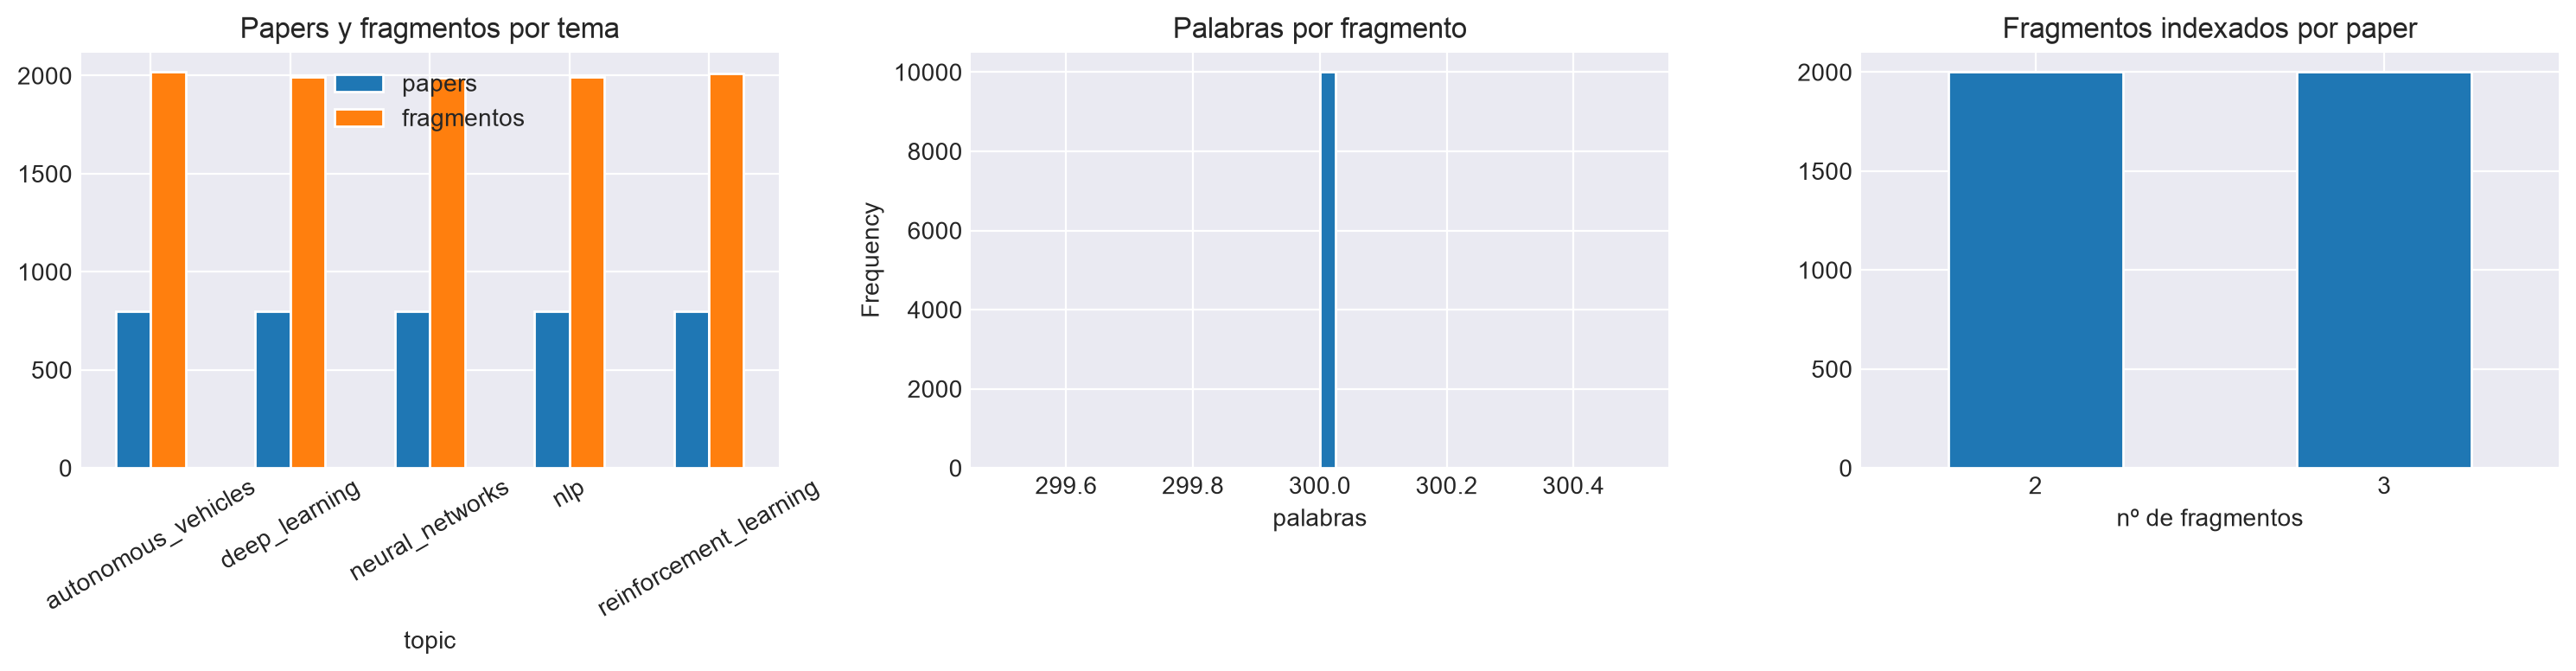


[autonomous_vehicles] doc_2504.07542_c00 · SydneyScapes: Image Segmentation for Australian Environments
SydneyScapes: Image Segmentation for Australian Environments Hongyu Lyu1, Julie Stephany Berrio1, Mao Shan, Stewart
Worrall The University of Sydney, Australian Centre for Robotics {h.lyu, j.berrio, m.shan, ∗† Abstract 2025 Autonomous
Vehicles (AVs) are being par- tially deployed and tested across various global locations, including China, the USA, Ger-
Apr many, France, Japan, Korea, and the UK, (a) Original image (b) Semantic segmentation but wi ...

[deep_learning] doc_2601.16107_c00 · Benchmarking Deep Learning Models for Raman Spectroscopy Across Open-Source Datasets
Benchmarking Deep Learning Models for Raman Spectroscopy Across Open-Source Datasets Adithya Sineesh1∗ Akshita Ramya
Kamsali1 1Purdue University, West Lafayette Abstract Deep learning classifiers for Raman spectroscopy are increasingly
reported to outperform classical chemometric approaches. However, their evaluati

In [66]:
summary = (docs_df.groupby('topic').size().rename('papers').to_frame()
           .join(chunks_df.groupby('topic').size().rename('fragmentos'))
           .join(chunks_df.groupby('topic')['n_words'].mean().round(0).rename('palabras/fragmento')))
summary.loc['TOTAL'] = [summary['papers'].sum(), summary['fragmentos'].sum(), chunks_df['n_words'].mean().round(0)]
display(summary.astype(int))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
summary.drop('TOTAL')[['papers', 'fragmentos']].plot.bar(ax=axes[0], rot=30)
axes[0].set_title('Papers y fragmentos por tema')
chunks_df['n_words'].plot.hist(bins=40, ax=axes[1])
axes[1].set_title('Palabras por fragmento'); axes[1].set_xlabel('palabras')
chunks_df.groupby('doc_id').size().value_counts().sort_index().plot.bar(ax=axes[2], rot=0)
axes[2].set_title('Fragmentos indexados por paper'); axes[2].set_xlabel('nº de fragmentos')
plt.tight_layout(); plt.show()

for topic, group in chunks_df.groupby('topic'):
    row = group.sample(1, random_state=SEED).iloc[0]
    print(f'\n[{topic}] {row["chunk_id"]} · {docs_by_id[row["doc_id"]]["title"][:90]}')
    print(textwrap.fill(row['text'][:450], 120) + ' ...')

---
# 2 · Preprocesado del texto
---

Transformamos cada fragmento en una lista de términos. **Las consultas seguirán el mismo procesamiento**, utilizando el modelo de expresiones y el diccionario ya construidos con el corpus.

| Paso | Operación |
|---|---|
| **Limpieza** | Normalizar Unicode y eliminar enlaces, correos y citas |
| **Lematización** | Obtener el lema y la categoría gramatical con spaCy |
| **Filtrado** | Conservar sustantivos, verbos, adjetivos y nombres propios alfabéticos; eliminar palabras vacías |
| **Expresiones** | Detectar combinaciones frecuentes con Gensim `Phrases` |
| **Vocabulario** | Eliminar términos demasiado escasos o extendidos |

Por ejemplo, *reinforcement learning* puede representarse como `reinforcement_learning` si el modelo detecta la expresión.

**Qué se gana y qué se pierde**

La lematización agrupa variantes de una palabra y el filtrado reduce términos poco informativos. Sin embargo, también pueden desaparecer conceptos útiles: cifras, símbolos o términos técnicos poco frecuentes.

No se ha medido por separado el efecto de cada transformación. Sus posibles consecuencias se revisarán en el análisis de errores.

> **Términos desconocidos.** Las consultas no amplían el vocabulario. Si todos sus términos quedan fuera del diccionario, no habrá evidencia léxica con la que recuperar artículos.

In [67]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

CITE_PAREN = re.compile(r'\([^()]{0,120}?\b(?:19|20)\d{2}[a-z]?\)')  # Ejemplo: (Smith et al., 2020)
CITE_BRACKET = re.compile(r'\[\s*\d+(?:\s*[,–-]\s*\d+)*\s*\]')  # Ejemplos: [12], [3, 5]

def wrangle_text(text):
    """Normaliza Unicode, elimina enlaces y citas y compacta espacios."""
    text = unicodedata.normalize('NFKC', text)
    for pattern in (URL_RE, EMAIL_RE, CITE_PAREN, CITE_BRACKET):
        text = pattern.sub(' ', text)
    return ' '.join(text.split())

def keep_token(tk):
    lemma = tk.lemma_.lower()
    return (tk.is_alpha and tk.pos_ in VALID_POS and not tk.is_stop
            and len(lemma) > 1 and lemma not in SPECIFIC_STW)

def prepare_data(texts, batch_size=64):
    """Devuelve una lista de lemas filtrados por cada texto."""
    wrangled = [wrangle_text(t) for t in texts]
    results = []
    for doc in tqdm(nlp.pipe(wrangled, batch_size=batch_size), total=len(wrangled), desc='spaCy'):
        results.append([tk.lemma_.lower() for tk in doc if keep_token(tk)])
    return results

example = chunks_df['text'].iloc[0]
print('ORIGINAL :', example[:300], '...')
print('LIMPIO   :', wrangle_text(example)[:300], '...')
tokens = [(tk.text, tk.lemma_.lower(), tk.pos_, tk.is_stop, keep_token(tk)) for tk in nlp(wrangle_text(example)[:600])][:25]
display(pd.DataFrame(tokens, columns=['token', 'lema', 'POS', 'stopword', 'se conserva']).T)

ORIGINAL : Multimodal Backdoor Attack on VLMs for Autonomous Driving via Graffiti and Cross-Lingual Triggers Jiancheng Wang1,2, Lidan Liang3, Yong Wang4, Zengzhen Su5, Haifeng Xia6, Yuanting Yan1,2*, Wei Wang6 *Corresponding author(s). E-mail(s): Contributing authors: 6 Abstract Visual language model (VLM) is  ...
LIMPIO   : Multimodal Backdoor Attack on VLMs for Autonomous Driving via Graffiti and Cross-Lingual Triggers Jiancheng Wang1,2, Lidan Liang3, Yong Wang4, Zengzhen Su5, Haifeng Xia6, Yuanting Yan1,2*, Wei Wang6 *Corresponding author(s). E-mail(s): Contributing authors: 6 Abstract Visual language model (VLM) is  ...


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
token,Multimodal,Backdoor,Attack,on,VLMs,for,Autonomous,Driving,via,Graffiti,...,Jiancheng,"Wang1,2",",",Lidan,Liang3,",",Yong,Wang4,",",Zengzhen
lema,multimodal,backdoor,attack,on,vlm,for,autonomous,driving,via,graffiti,...,jiancheng,"wang1,2",",",lidan,liang3,",",yong,wang4,",",zengzhen
POS,PROPN,PROPN,PROPN,ADP,NOUN,ADP,PROPN,PROPN,ADP,PROPN,...,PROPN,NOUN,PUNCT,PROPN,PROPN,PUNCT,PROPN,NOUN,PUNCT,PROPN
stopword,False,False,False,True,False,True,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
se conserva,True,True,True,False,True,False,True,True,False,True,...,True,False,False,True,False,False,True,False,False,True


In [68]:
LEMMAS_FILE = os.path.join(DATA_DIR, 'chunk_lemmas.jsonl')
signature = {'spacy': spacy.__version__, 'model': str(nlp.meta.get('version')), 'pos': sorted(VALID_POS),
             'stopwords': sorted(SPECIFIC_STW), 'chunks': len(chunks_df), 'first': chunks_df['chunk_id'].iloc[0]}

chunk_lemmas = None
if os.path.exists(LEMMAS_FILE):
    rows = read_jsonl(LEMMAS_FILE)
    if rows and rows[0] == signature and len(rows) == len(chunks_df) + 1:
        chunk_lemmas = rows[1:]
        print('Lemas leídos de la caché', LEMMAS_FILE)
if chunk_lemmas is None:
    chunk_lemmas = prepare_data(chunks_df['text'].tolist())
    write_jsonl(LEMMAS_FILE, [signature] + chunk_lemmas)

print(chunk_lemmas[0][:30])

Lemas leídos de la caché ./data/chunk_lemmas.jsonl
['multimodal', 'backdoor', 'attack', 'vlm', 'autonomous', 'driving', 'graffiti', 'cross', 'lingual', 'triggers', 'jiancheng', 'lidan', 'yong', 'zengzhen', 'haifeng', 'yuante', 'wei', 'corresponding', 'contribute', 'author', 'abstract', 'visual', 'language', 'model', 'vlm', 'integrate', 'safety', 'critical', 'system', 'autonomous']


N-gramas más frecuentes: ['reinforcement_learning', 'deep_learning', 'neural_network', 'large_language', 'real_world', 'autonomous_vehicle', 'real_time', 'machine_learning', 'state_art', 'autonomous_driving', 'large_scale', 'multi_agent', 'artificial_intelligence', 'time_step', 'end_end']
Vocabulario: 81984 términos -> 16669 tras filtrar (aparecen en >= 5 fragmentos y en <= 50%)
Términos por fragmento: media 140, mín 34, máx 229 · fragmentos vacíos: 0


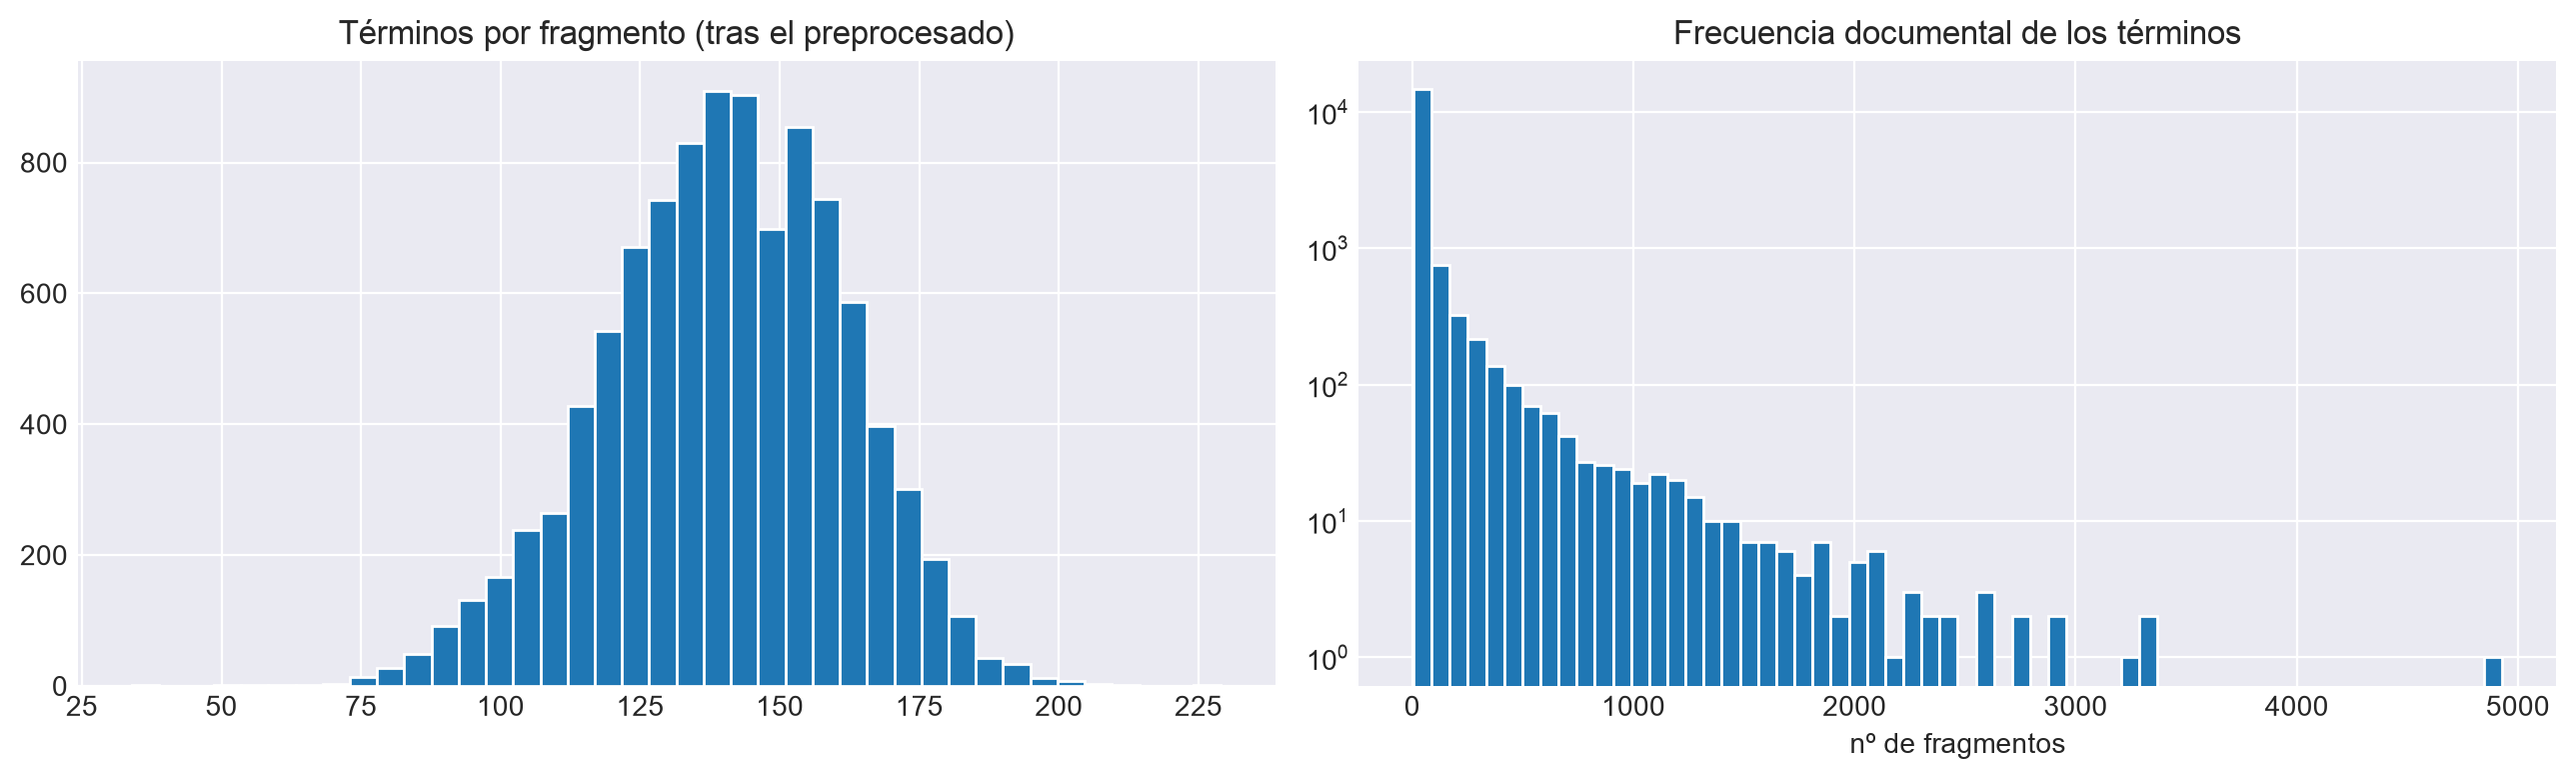

,10,366,395,318,102,346,81,101,493,746
término,base,performance,training,datum,task,learn,provide,system,framework,dataset
n_fragmentos,4928,3346,3314,3277,2942,2902,2745,2716,2607,2605


In [69]:
from gensim.models.phrases import Phrases
from gensim.corpora import Dictionary

phrase_model = Phrases(chunk_lemmas, min_count=PHRASES_MIN_COUNT, threshold=PHRASES_THRESHOLD)
corpus = [phrase_model[doc] for doc in chunk_lemmas]
top_phrases = Counter(t for doc in corpus for t in doc if '_' in t)
print('N-gramas más frecuentes:', [p for p, _ in top_phrases.most_common(15)])

D = Dictionary(corpus)
n_before = len(D)
D.filter_extremes(no_below=NO_BELOW, no_above=NO_ABOVE, keep_n=None)
print(f'Vocabulario: {n_before} términos -> {len(D)} tras filtrar (aparecen en >= {NO_BELOW} fragmentos y en <= {NO_ABOVE:.0%})')

chunk_bow = [D.doc2bow(doc) for doc in corpus]

def preprocess(texts):
    """Pipeline completo para textos nuevos (consultas): limpieza -> spaCy -> n-gramas. El diccionario se aplica luego con D.doc2bow."""
    return [phrase_model[tokens] for tokens in prepare_data(texts)]

lengths = np.array([sum(c for _, c in bow) for bow in chunk_bow])
print(f'Términos por fragmento: media {lengths.mean():.0f}, mín {lengths.min()}, máx {lengths.max()} · fragmentos vacíos: {(lengths == 0).sum()}')

df_terms = pd.DataFrame({'término': [D[i] for i in D.keys()], 'n_fragmentos': [D.dfs[i] for i in D.keys()]})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(lengths, bins=40); axes[0].set_title('Términos por fragmento (tras el preprocesado)')
axes[1].hist(df_terms['n_fragmentos'], bins=60, log=True); axes[1].set_title('Frecuencia documental de los términos'); axes[1].set_xlabel('nº de fragmentos')
plt.tight_layout(); plt.show()
display(df_terms.sort_values('n_fragmentos', ascending=False).head(10).T)

---
# 3 · Consultas de evaluación
---

La tarea es de **búsqueda de un documento conocido** (*known-item retrieval*): cada consulta se genera a partir de un artículo y se comprueba si el sistema consigue recuperarlo.

**Construcción del conjunto de prueba**

1. Muestrear fragmentos de los cinco temas, con un solo fragmento por artículo.

2. Generar consultas con un LLM a partir del título, el resumen y el fragmento. Se alternan formulaciones breves, conversacionales y detalladas.

3. Aplicar controles automáticos de copia, longitud, coincidencia de términos y coherencia.

4. Revisar manualmente al menos diez candidatas y registrar las decisiones.

5. Guardar las aceptadas en `queries.jsonl` y la revisión en `queries_review.csv`.

Se generan más candidatas que el mínimo exigido para poder descartar las inadecuadas. **El conjunto final debe contener al menos treinta consultas.**

> **Cómo entender la relevancia.** Solo se anota como relevante el artículo de origen. Otro artículo podría responder bien a la consulta y, aun así, no contar como acierto. La evaluación mide la recuperación del artículo conocido.

In [70]:
AREA_NAMES = {'autonomous_vehicles': 'autonomous vehicles and self-driving', 'reinforcement_learning': 'reinforcement learning',
              'nlp': 'natural language processing', 'neural_networks': 'neural networks', 'deep_learning': 'deep learning'}

STYLES = {
    'simple': ("SHORT and simple: 4 to 8 words, a plain topic phrase like a quick keyword search that names the main "
               "subject of the paper (for example: graph neural networks for molecule property prediction). "
               "Do not chain technical terms and do not use 'with ... and ...' constructions.", 3, 10, 2),
    'conversational': ("a natural sentence of 8 to 14 words that starts like 'I am researching ...', 'I am looking for ...' "
                       "or 'Papers about ...' and states the single main idea of the paper (for example: I am researching "
                       "methods to speed up protein folding simulations).", 6, 20, 2),
    'detailed': ("a detailed query of 12 to 20 words that names the problem and the specific method or contribution.", 8, 30, 3),
}
STYLE_PATTERN = ['simple', 'conversational', 'detailed', 'simple', 'simple',
                 'conversational', 'detailed', 'simple', 'conversational', 'detailed']

GEN_PROMPT = """You are helping to build a test set for a search engine over scientific papers (arXiv).
You will receive the title and abstract of a paper and an excerpt from its full text.
Write ONE search query, in English, that a researcher who is looking for THIS paper could type.
Style of the query: {style_instruction}

Rules:
- The query must describe what the paper is about, so that it clearly belongs to the research area "{area}".
- Use the excerpt only to decide which topic of the paper to refer to; stay consistent with the paper as a whole.
- Use your own words: do NOT copy phrases from the title, the abstract or the excerpt; prefer paraphrases and synonyms.
- Do not include the title, author names, or numbers of sections, tables or figures.
- Output only the query, with no quotes and no explanation.

Research area: {area}
Title: {title}
Abstract: {abstract}
Excerpt:
{excerpt}
"""

JUDGE_PROMPT = """You are checking the quality of a test set for a search engine over scientific papers.
Research area: {area}
Paper title: {title}
Paper abstract: {abstract}

Search query: {query}

Rate the query with two integers from 1 to 5:
"match": how well the query describes THIS paper (1 = unrelated or about a different subject, 5 = clearly describes this paper's problem or contribution).
"specific": how specific the query is (1 = so generic that hundreds of papers in the area would match, 5 = it identifies a narrow set of papers).
Answer only with JSON, for example {{"match": 4, "specific": 3}}"""

_api_key = [None]

def api_key():
    """Obtiene la clave del entorno, de secretos de Colab o por teclado; la conserva en memoria."""
    if _api_key[0] is None:
        key = os.environ.get('UC3M_API_KEY')
        if not key and IN_COLAB:
            try:
                from google.colab import userdata
                key = userdata.get('UC3M_API_KEY')
            except Exception:
                key = None
        if not key:
            import getpass
            key = getpass.getpass('API key del servidor UC3M (está en el enunciado, sección 7): ')
        _api_key[0] = key
    return _api_key[0]

if not VERIFY_SSL:
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

def call_llm(prompt, model, temperature=0.2, retries=3):
    url = UC3M_URL if LLM_BACKEND == 'uc3m' else OLLAMA_URL
    headers = {'X-API-KEY': api_key()} if LLM_BACKEND == 'uc3m' else {}
    payload = {'model': model, 'prompt': prompt, 'stream': False, 'options': {'temperature': temperature, 'seed': SEED}}
    error = None
    for attempt in range(retries):
        try:
            r = requests.post(url, headers=headers, json=payload, timeout=180, verify=VERIFY_SSL)
            r.raise_for_status()
            return r.json()['response']
        except (requests.RequestException, KeyError, ValueError) as e:
            error = type(e).__name__
            time.sleep(2 ** attempt)
    raise RuntimeError(f'El LLM no responde ({error})')

def strip_thinking(text):
    return re.sub(r'<think>.*?</think>', '', text, flags=re.S).strip()

def clean_query(text):
    lines = strip_thinking(text).splitlines()
    text = lines[0] if lines else ''
    text = re.sub(r'^\W*(search\s+)?query\s*:\s*', '', text, flags=re.I)
    return text.strip().strip('"\'`').strip()

def parse_judge(text):
    text = strip_thinking(text)
    m, s = re.search(r'"?match"?\s*:\s*([1-5])', text), re.search(r'"?specific"?\s*:\s*([1-5])', text)
    return (int(m.group(1)) if m else None, int(s.group(1)) if s else None)

def sample_source_chunks(n_total, seed):
    """Fragmentos al azar, repartidos a partes iguales entre temas y con un único fragmento por paper."""
    rng = random.Random(seed)
    topics = list(TOPICS)
    quota = {t: n_total // len(topics) + (i < n_total % len(topics)) for i, t in enumerate(topics)}
    picked = []
    for t in topics:
        pool = chunks_df[(chunks_df['topic'] == t) & (chunks_df['n_words'] >= 0.8 * CHUNK_WORDS)]
        doc_ids = sorted(pool['doc_id'].unique())
        rng.shuffle(doc_ids)
        for d in doc_ids[:quota[t]]:
            picked.append(pool[pool['doc_id'] == d].sample(1, random_state=rng.randrange(10 ** 6)).iloc[0])
    rng.shuffle(picked)
    return picked

In [71]:
def generate_candidates():
    cands = []
    for i, row in enumerate(tqdm(sample_source_chunks(N_CANDIDATES, SEED + 2), desc='consultas'), 1):
        doc = docs_by_id[row['doc_id']]
        style = STYLE_PATTERN[(i - 1) % len(STYLE_PATTERN)]
        fields = dict(area=AREA_NAMES[row['topic']], title=doc['title'], abstract=doc['abstract'])
        try:
            query = clean_query(call_llm(GEN_PROMPT.format(excerpt=row['text'], style_instruction=STYLES[style][0], **fields),
                                         LLM_MODEL, temperature=0.3))
            match, specific = parse_judge(call_llm(JUDGE_PROMPT.format(query=query, **fields), JUDGE_MODEL, temperature=0.0))
        except RuntimeError as e:
            print(f'  candidata {i} omitida: {e}')
            continue
        cands.append({'qid': f'q{i:02d}', 'query': query, 'relevant_ids': [row['doc_id']], 'source_chunk': row['chunk_id'],
                      'topic': row['topic'], 'style': style, 'judge_match': match, 'judge_specific': specific})
    return cands

if os.path.exists(QUERIES_CAND_FILE) and not REGENERATE_QUERIES:
    print('Reutilizando', QUERIES_CAND_FILE, '(así la revisión manual sigue siendo válida). REGENERATE_QUERIES=True para rehacerlas.')
    cands = read_jsonl(QUERIES_CAND_FILE)
else:
    cands = generate_candidates()
    write_jsonl(QUERIES_CAND_FILE, cands)
print(len(cands), 'candidatas')
print(pd.Series([c['style'] for c in cands]).value_counts().to_string())

Reutilizando ./data/candidates_queries.jsonl (así la revisión manual sigue siendo válida). REGENERATE_QUERIES=True para rehacerlas.
60 candidatas
simple            24
conversational    18
detailed          18


## 3.1 · Controles automáticos

Se comprueba si cada consulta:

- copia alguna secuencia de cuatro palabras del texto de referencia;
- comparte suficientes lemas con el título y el resumen;
- cumple los límites de longitud de su estilo;
- recibe una valoración suficiente de coherencia y especificidad del LLM.

Las candidatas que incumplen algún criterio se marcan como `revisar`. **Esta etiqueta orienta la inspección; no equivale a un descarte definitivo.**

Las tablas por tema y estilo permiten comprobar si los filtros dejan un conjunto desequilibrado.

In [72]:
def words_of(text):
    return re.findall(r'[a-z0-9]+', text.lower())

def ngram_copies(query, reference, n=4):
    """Nº de grupos de n palabras consecutivas de la consulta que aparecen literalmente en el texto de referencia."""
    q, r = words_of(query), words_of(reference)
    ref_grams = {tuple(r[i:i + n]) for i in range(len(r) - n + 1)}
    return sum(tuple(q[i:i + n]) in ref_grams for i in range(len(q) - n + 1))

chunk_text_by_id = dict(zip(chunks_df['chunk_id'], chunks_df['text']))
cand_by_id = {c['qid']: c for c in cands}

# Comparar lemas individuales, antes de formar n-gramas.
q_lemmas = prepare_data([c['query'] for c in cands])
a_lemmas = prepare_data([docs_by_id[c['relevant_ids'][0]]['title'] + '. ' + docs_by_id[c['relevant_ids'][0]]['abstract'] for c in cands])

for c, ql, al in zip(cands, q_lemmas, a_lemmas):
    doc = docs_by_id[c['relevant_ids'][0]]
    reference = doc['title'] + ' ' + doc['abstract']
    _, min_w, max_w, min_specific = STYLES[c['style']]
    c['n_words'] = len(c['query'].split())
    c['copy4'] = ngram_copies(c['query'], chunk_text_by_id[c['source_chunk']]) + ngram_copies(c['query'], reference)
    c['shared_terms'] = len(set(ql) & set(al))
    reasons = []
    if not min_w <= c['n_words'] <= max_w:
        reasons.append(f'longitud ({c["n_words"]} palabras; estilo {c["style"]}: {min_w}-{max_w})')
    if c['copy4'] > 0:
        reasons.append('copia literal de 4+ palabras')
    if c['shared_terms'] < MIN_SHARED_TERMS:
        reasons.append('casi sin términos del título/resumen')
    if c['judge_match'] is None or c['judge_match'] < MIN_JUDGE_MATCH:
        reasons.append(f'el LLM no ve que describa el paper (match={c["judge_match"]})')
    if c['judge_specific'] is None or c['judge_specific'] < min_specific:
        reasons.append(f'demasiado genérica (specific={c["judge_specific"]}, mínimo {min_specific})')
    c['auto'] = 'ok' if not reasons else 'revisar'
    c['reasons'] = '; '.join(reasons)

auto_df = pd.DataFrame(cands)[['qid', 'topic', 'style', 'query', 'judge_match', 'judge_specific', 'shared_terms', 'copy4', 'auto', 'reasons']]
print(f'{(auto_df["auto"] == "ok").sum()} de {len(auto_df)} candidatas superan todos los controles automáticos')
print(pd.crosstab(auto_df['topic'], auto_df['auto']).to_string())
print(pd.crosstab(auto_df['style'], auto_df['auto']).to_string())
display(auto_df.sort_values(['auto', 'topic']).reset_index(drop=True))

spaCy:   0%|          | 0/60 [00:00<?, ?it/s]

spaCy:   0%|          | 0/60 [00:00<?, ?it/s]

18 de 60 candidatas superan todos los controles automáticos
auto                    ok  revisar
topic                              
autonomous_vehicles      3        9
deep_learning            2       10
neural_networks          5        7
nlp                      4        8
reinforcement_learning   4        8
auto            ok  revisar
style                      
conversational  10        8
detailed         8       10
simple           0       24


,qid,topic,style,query,judge_match,judge_specific,shared_terms,copy4,auto,reasons
0,q09,autonomous_vehicles,conversational,Evaluating robustness of autonomous power system agents under rare contingencies and degraded observability conditions.,4,2,5,0,ok,
1,q46,autonomous_vehicles,conversational,Self-driving vehicles migrating between roadside units with dynamic pruning for efficient computation and exploration.,5,4,9,0,ok,
2,q53,autonomous_vehicles,detailed,Improving autonomous driving with reinforcement learning by integrating trajectory planning and kinematic feasibility checks for safer navigation,5,4,11,0,ok,
3,q02,deep_learning,conversational,Can deep learning models distinguish between high-quality and low-quality news articles based on linguistic features?,5,4,12,0,ok,
4,q03,deep_learning,detailed,deep learning vs feature engineering for coin grading with limited data and class imbalance,5,4,8,0,ok,
5,q06,neural_networks,conversational,Evaluating neural network performance on generated optimization test functions with diverse landscape properties.,5,4,10,0,ok,
6,q07,neural_networks,detailed,Biologically plausible neural network for anomaly detection with adaptive threshold and Laplacian regularization of synaptic connections,5,4,5,0,ok,
7,q19,neural_networks,conversational,fractal dimensions in neural network layers under varying scales and their implications for hierarchical abstraction,5,4,8,0,ok,
8,q56,neural_networks,conversational,Optimisation strategies for multilayer perceptrons in supervised learning from an information-theoretic perspective,5,4,6,0,ok,
9,q57,neural_networks,detailed,Training neural networks with spike-based computations using random feature methods for efficient and accurate time series forecasting,5,4,11,0,ok,


## 3.2 · Revisión manual

El protocolo contempla la revisión de **al menos diez consultas**, repartidas entre los cinco temas y priorizando las marcadas como `revisar`.

`inspect_query(qid)` muestra la consulta, el título, el resumen y el fragmento de origen. Los criterios de revisión son:

- **Coherencia:** ¿el artículo respalda lo que pide la consulta?
- **Especificidad:** ¿la consulta distingue este trabajo de otros del área?
- **Reformulación:** ¿evita copiar el título o el resumen?
- **Ambigüedad:** ¿otro artículo podría responder igual de bien?

Las decisiones se registran en `REVIEW` con una etiqueta y una justificación:

```python
'q07': ('discard', 'Demasiado genérica: solo identifica el área de investigación')
'q03': ('ok', 'Describe la tarea y la contribución del artículo sin copiar el título')
```

La decisión humana prevalece para las consultas revisadas. Las demás solo se conservan si superan todos los controles automáticos.

El registro distingue las consultas revisadas manualmente de las aceptadas mediante los controles automáticos.

In [73]:
def inspect_query(qid):
    c = cand_by_id[qid]
    doc = docs_by_id[c['relevant_ids'][0]]
    print(f'[{qid}] tema: {c["topic"]} · {c["relevant_ids"][0]} · auto: {c["auto"]} {c["reasons"]}')
    print('TÍTULO  :', doc['title'])
    print('RESUMEN :', textwrap.fill(doc['abstract'], 120, subsequent_indent=' ' * 10))
    print('CONSULTA:', c['query'], f'  (match={c["judge_match"]}, specific={c["judge_specific"]})')
    print('FRAGMENTO DE ORIGEN:', textwrap.fill(chunk_text_by_id[c['source_chunk']][:700], 120) + ' ...\n')

for qid in [c['qid'] for c in cands if c['auto'] == 'revisar'][:3]:
    inspect_query(qid)

[q01] tema: reinforcement_learning · doc_2504.03160 · auto: revisar longitud (15 palabras; estilo simple: 3-10); copia literal de 4+ palabras
TÍTULO  : DeepResearcher: Scaling Deep Research via Reinforcement Learning in Real-world Environments
RESUMEN : Large Language Models (LLMs) equipped with web search capabilities have demonstrated impressive potential for deep
          research tasks. However, current approaches predominantly rely on either manually engineered prompts (prompt
          engineering-based) with brittle performance or reinforcement learning within controlled Retrieval-Augmented
          Generation (RAG) environments (RAG-based) that fail to capture the complexities of real-world interaction. In
          this paper, we introduce DeepResearcher, the first comprehensive framework for end-to-end training of LLM-
          based deep research agents through scaling reinforcement learning (RL) in real-world environments with
          authentic web search interactions.

In [74]:
REVIEW = {
}

In [75]:
unknown = [q for q in REVIEW if q not in cand_by_id]
bad_values = [q for q, (decision, _) in REVIEW.items() if decision not in ('ok', 'discard')]
assert not unknown, f'qid inexistentes en REVIEW: {unknown}'
assert not bad_values, f"la decisión debe ser 'ok' o 'discard': {bad_values}"

def decide(c):
    """Decisión humana si la hay; si no, sólo se conserva lo que supera todos los controles automáticos."""
    if c['qid'] in REVIEW:
        return REVIEW[c['qid']][0]
    return 'ok' if c['auto'] == 'ok' else 'discard'

for c in cands:
    c['final'] = decide(c)
kept = [c for c in cands if c['final'] == 'ok']

write_jsonl(QUERIES_FILE, [{'qid': c['qid'], 'query': c['query'], 'relevant_ids': c['relevant_ids'], 'source_chunk': c['source_chunk']}
                           for c in kept])
pd.DataFrame([{'qid': c['qid'], 'topic': c['topic'], 'query': c['query'], 'auto': c['auto'], 'auto_reasons': c['reasons'],
               'judge_match': c['judge_match'], 'judge_specific': c['judge_specific'],
               'manual_decision': REVIEW.get(c['qid'], ('', ''))[0], 'manual_note': REVIEW.get(c['qid'], ('', ''))[1],
               'final': c['final']} for c in cands]).astype({'judge_match': 'Int64', 'judge_specific': 'Int64'}).to_csv(REVIEW_FILE, index=False)

n_reviewed = len(REVIEW)
per_topic = Counter(c['topic'] for c in kept)
print(f'Candidatas: {len(cands)} · revisadas a mano: {n_reviewed} · conservadas: {len(kept)} · guardadas en {QUERIES_FILE}')
print('Consultas finales por tema:', {t: per_topic.get(t, 0) for t in TOPICS})
if n_reviewed < MIN_REVIEWED:
    print(f'AVISO: FALTA LA REVISIÓN MANUAL: {n_reviewed} de {MIN_REVIEWED} consultas revisadas. Completad REVIEW y volved a ejecutar desde la celda de REVIEW hasta el final.')
if len(kept) < N_QUERIES_MIN:
    print(f'AVISO: sólo {len(kept)} consultas válidas (mínimo {N_QUERIES_MIN}): subid N_CANDIDATES y regenerad (REGENERATE_QUERIES=True).')
if any(per_topic.get(t, 0) < MIN_QUERIES_PER_TOPIC for t in TOPICS):
    print(f'AVISO: algún tema tiene menos de {MIN_QUERIES_PER_TOPIC} consultas: el conjunto de test no cubre bien los 5 temas.')

coherence = pd.DataFrame([{'tema': c['topic'], 'qid': c['qid'], 'consulta': c['query'],
                           'paper relevante': docs_by_id[c['relevant_ids'][0]]['title'][:90]} for c in kept]).sort_values(['tema', 'qid'])
display(coherence.reset_index(drop=True))

Candidatas: 60 · revisadas a mano: 0 · conservadas: 18 · guardadas en ./queries.jsonl
Consultas finales por tema: {'autonomous_vehicles': 3, 'reinforcement_learning': 4, 'nlp': 4, 'neural_networks': 5, 'deep_learning': 2}
AVISO: FALTA LA REVISIÓN MANUAL: 0 de 10 consultas revisadas. Completad REVIEW y volved a ejecutar desde la celda de REVIEW hasta el final.
AVISO: sólo 18 consultas válidas (mínimo 30): subid N_CANDIDATES y regenerad (REGENERATE_QUERIES=True).
AVISO: algún tema tiene menos de 5 consultas: el conjunto de test no cubre bien los 5 temas.


,tema,qid,consulta,paper relevante
0,autonomous_vehicles,q09,Evaluating robustness of autonomous power system agents under rare contingencies and degraded observability conditions.,Engineering Trustworthy Agentic AI for Critical Systems
1,autonomous_vehicles,q46,Self-driving vehicles migrating between roadside units with dynamic pruning for efficient computation and exploration.,TinyMA-IEI-PPO: Exploration Incentive-Driven Multi-Agent DRL with Self-Adaptive Pruning fo
2,autonomous_vehicles,q53,Improving autonomous driving with reinforcement learning by integrating trajectory planning and kinematic feasibility checks for safer navigation,PlanRL: A Trajectory Planning Architecture for Reinforcement Learning-based Driving Expert
3,deep_learning,q02,Can deep learning models distinguish between high-quality and low-quality news articles based on linguistic features?,"Classification of worldwide news articles by perceived quality, 2018-2024"
4,deep_learning,q03,deep learning vs feature engineering for coin grading with limited data and class imbalance,Feature Engineering vs. Deep Learning for Automated Coin Grading: A Comparative Study on S
5,neural_networks,q06,Evaluating neural network performance on generated optimization test functions with diverse landscape properties.,Automatic Design of Optimization Test Problems with Large Language Models
6,neural_networks,q07,Biologically plausible neural network for anomaly detection with adaptive threshold and Laplacian regularization of synaptic connections,Multiscale Astrocyte Network Calcium Dynamics for Biologically Plausible Intelligence in A
7,neural_networks,q19,fractal dimensions in neural network layers under varying scales and their implications for hierarchical abstraction,Recursive Self-Similarity in Deep Weight Spaces of Neural Architectures: A Fractal and Coa
8,neural_networks,q56,Optimisation strategies for multilayer perceptrons in supervised learning from an information-theoretic perspective,Information flow in multilayer perceptrons: an in-depth analysis
9,neural_networks,q57,Training neural networks with spike-based computations using random feature methods for efficient and accurate time series forecasting,Random Feature Spiking Neural Networks


---
# 4 · Métodos de recuperación
---

Comparamos dos formas de puntuar **la misma evidencia léxica**:

- **TF-IDF + coseno:** pondera los términos y compara la orientación de los vectores.
- **BM25:** incorpora saturación de frecuencia y normalización por longitud.

Ambos puntúan fragmentos. En la evaluación se agruparán sus puntuaciones para ordenar artículos completos.

## 4.1 · TF-IDF y similitud coseno

Utilizamos `TfidfModel` de Gensim con frecuencia bruta e IDF logarítmico. El peso de un término $t$ en un fragmento $c$ es:

$$w_{t,c}=f(t,c)\log_2\left(\frac{N}{\operatorname{df}(t)}\right).$$

- $f(t,c)$: número de apariciones del término en el fragmento.
- $N$: número de fragmentos del índice.
- $\operatorname{df}(t)$: número de fragmentos que contienen el término.

**La consulta y los fragmentos se normalizan a norma L2.** Su producto escalar equivale entonces a la similitud coseno:

$$s(q,c)=\frac{\mathbf{w}_q^{\mathsf T}\mathbf{w}_c}{\lVert\mathbf{w}_q\rVert_2\lVert\mathbf{w}_c\rVert_2}.$$

El método necesita términos compartidos. No reconoce por sí solo que dos palabras distintas puedan expresar el mismo concepto.

In [76]:
from gensim.models import TfidfModel
from gensim.matutils import corpus2csc

tfidf = TfidfModel(chunk_bow)
n_chunks, n_terms = len(chunk_bow), len(D)

# Filas: fragmentos. Columnas: términos.
X_counts = corpus2csc(chunk_bow, num_terms=n_terms, num_docs=n_chunks).T.tocsr()
X_tfidf = corpus2csc(tfidf[chunk_bow], num_terms=n_terms, num_docs=n_chunks).T.tocsr()
print(f'Matriz fragmentos x términos: {X_counts.shape}, {100 * X_counts.nnz / (n_chunks * n_terms):.2f} % de entradas no nulas')

def tfidf_scores(tokens):
    """Similitud coseno entre una consulta (lista de términos) y todos los fragmentos."""
    vec = np.zeros(n_terms)
    for term_id, weight in tfidf[D.doc2bow(tokens)]:
        vec[term_id] = weight
    return X_tfidf @ vec

Matriz fragmentos x términos: (10000, 16669), 0.60 % de entradas no nulas


## 4.2 · BM25

Implementamos Okapi BM25 con el IDF de Lucene:

$$s(q,c)=\sum_{t\in\operatorname{unique}(q)}\operatorname{IDF}(t)\frac{f(t,c)(k_1+1)}{f(t,c)+k_1\left(1-b+b\frac{|c|}{\operatorname{avgdl}}\right)}.$$

$$\operatorname{IDF}(t)=\ln\left(1+\frac{N-\operatorname{df}(t)+0.5}{\operatorname{df}(t)+0.5}\right).$$

La notación de frecuencia e IDF es la misma que en TF-IDF. Aquí, $|c|$ es la longitud del fragmento según la matriz de conteos del vocabulario filtrado y $\operatorname{avgdl}$ es su media.

**Parámetros del baseline**

| Parámetro | Valor | Función |
|---|---|---|
| $k_1$ | 1.5 | Regula la saturación: repetir un término aporta cada vez menos |
| $b$ | 0.75 | Regula la normalización por longitud |

La suma recorre los términos distintos de la consulta. Todas las estadísticas se calculan **sobre fragmentos**, no sobre artículos completos.

La celda de verificación contrasta la implementación matricial con la fórmula término a término. Esto comprueba consistencia numérica, no calidad de recuperación.

In [77]:
class BM25:
    """Okapi BM25 (IDF de Lucene) sobre una matriz dispersa de conteos fragmentos x términos."""
    def __init__(self, counts, k1=1.5, b=0.75):
        counts = sparse.csr_matrix(counts)
        self.k1, self.b = k1, b
        self.n_docs = counts.shape[0]
        self.doc_len = np.asarray(counts.sum(axis=1)).ravel().astype(float)
        self.avgdl = self.doc_len.mean()
        df = np.asarray((counts > 0).sum(axis=0)).ravel()
        self.idf = np.log1p((self.n_docs - df + 0.5) / (df + 0.5))
        coo = counts.tocoo()
        tf = coo.data.astype(float)
        norm = k1 * (1 - b + b * self.doc_len[coo.row] / self.avgdl)
        weights = self.idf[coo.col] * tf * (k1 + 1) / (tf + norm)
        self.W = sparse.csc_matrix((weights, (coo.row, coo.col)), shape=counts.shape)

    def scores(self, term_ids):
        """Puntuación de todos los fragmentos para una consulta (ids de sus términos distintos)."""
        term_ids = sorted(set(term_ids))
        if not term_ids:
            return np.zeros(self.n_docs)
        return np.asarray(self.W[:, term_ids].sum(axis=1)).ravel()

bm25 = BM25(X_counts, k1=BM25_K1, b=BM25_B)
bm25_label = f'BM25 (k1={BM25_K1}, b={BM25_B})'

def query_term_ids(tokens):
    return [term_id for term_id, _ in D.doc2bow(tokens)]

def bm25_scores(tokens, model=None):
    return (model or bm25).scores(query_term_ids(tokens))

In [78]:
# Contrastar la implementación matricial con la fórmula explícita.
X_csc = X_counts.tocsc()

def bm25_explicit(term_ids, row, k1=BM25_K1, b=BM25_B):
    dl = X_counts[row].sum()
    avgdl = X_counts.sum() / n_chunks
    score = 0.0
    for t in set(term_ids):
        df_t = X_csc[:, t].nnz
        idf = math.log(1 + (n_chunks - df_t + 0.5) / (df_t + 0.5))
        f = X_counts[row, t]
        score += idf * f * (k1 + 1) / (f + k1 * (1 - b + b * dl / avgdl))
    return score

rng_check = np.random.default_rng(SEED)
sample_terms = [int(t) for t in rng_check.choice(n_terms, size=6, replace=False)]
sample_rows = [int(r) for r in rng_check.choice(n_chunks, size=20, replace=False)]
ours = bm25.scores(sample_terms)
assert all(np.isclose(ours[r], bm25_explicit(sample_terms, r)) for r in sample_rows), 'BM25 no coincide con la fórmula'
print('OK: BM25 coincide con la fórmula explícita en', len(sample_rows), 'fragmentos')

OK: BM25 coincide con la fórmula explícita en 20 fragmentos


---
# 5 · Evaluación
---

Queremos responder a dos preguntas:

1. **¿Se recupera el artículo entre los primeros resultados?** Lo medimos con Recall@5 y Recall@10.
2. **¿En qué posición aparece?** Lo medimos con MRR@10 y MRR@100.

Evaluamos los dos métodos sobre las mismas consultas y acompañamos las medias con intervalos de incertidumbre y resultados por tema.

## 5.1 · Del ranking de fragmentos al ranking de artículos

Un artículo puede tener varios fragmentos. Para evitar resultados duplicados, recibe **la mayor puntuación de sus fragmentos**:

$$s(q,d)=\max_{c\in C(d)}s(q,c).$$

Los artículos se ordenan por esa puntuación. Solo se conservan puntuaciones positivas, hasta un máximo de cien resultados; los empates siguen el orden estable de la implementación.

**Recall@K**

Mide qué fracción de los relevantes aparece en las primeras $K$ posiciones, promediada sobre consultas:

$$\operatorname{Recall@K}=\frac{1}{|Q|}\sum_{q\in Q}\frac{|R_q\cap L_q^K|}{|R_q|}.$$

$R_q$ contiene los artículos relevantes anotados y $L_q^K$ los primeros $K$ resultados. Como hay **un solo relevante por consulta**, la métrica es la proporción de consultas que recuperan su artículo de origen dentro del corte.

**MRR@K**

Si el primer relevante aparece en la posición $r_q$, la consulta aporta $1/r_q$. Si queda fuera del corte, aporta cero:

$$\operatorname{MRR@K}=\frac{1}{|Q|}\sum_{q\in Q}\begin{cases}1/r_q,&r_q\leq K,\\0,&\text{en otro caso}.\end{cases}$$

Por ejemplo, encontrarlo en primera posición aporta 1; en quinta, 0.2. Se reportan cortes en 10 y 100, no un MRR sobre un ranking ilimitado.

> **Diagnóstico adicional:** también se mide si aparece el fragmento que originó la consulta. Recuperar otro fragmento del mismo artículo puede ser útil, aunque no cuente como acierto en esta medida.

In [79]:
queries = read_jsonl(QUERIES_FILE)
assert queries, 'queries.jsonl está vacío: revisad la sección 3'
query_tokens = preprocess([q['query'] for q in queries])
relevants = [set(q['relevant_ids']) for q in queries]
source_chunks = [q['source_chunk'] for q in queries]
q_topic = [docs_by_id[q['relevant_ids'][0]]['topic'] for q in queries]

print(f'{len(queries)} consultas')
for q, toks in list(zip(queries, query_tokens))[:3]:
    print(f'  {q["query"]}\n   -> {toks}')

doc_ids = docs_df['doc_id'].tolist()
doc_index = {d: i for i, d in enumerate(doc_ids)}
chunk_doc_idx = chunks_df['doc_id'].map(doc_index).to_numpy()
chunk_ids = chunks_df['chunk_id'].to_numpy()

def doc_scores_from_chunks(chunk_scores):
    """Asigna a cada artículo la puntuación máxima de sus fragmentos."""
    scores = np.full(len(doc_ids), -np.inf)
    np.maximum.at(scores, chunk_doc_idx, chunk_scores)
    return scores

def top_docs(chunk_scores, k=MAX_DEPTH):
    """Devuelve hasta k artículos únicos con puntuación positiva, en orden decreciente."""
    scores = doc_scores_from_chunks(chunk_scores)
    order = np.argsort(-scores, kind='stable')[:k]
    return [doc_ids[i] for i in order if scores[i] > 0]

def top_chunks(chunk_scores, k=MAX_DEPTH):
    order = np.argsort(-chunk_scores, kind='stable')[:k]
    return [chunk_ids[i] for i in order if chunk_scores[i] > 0]

def recalls_at_k(rankings, relevants, k):
    """Recall@K de cada consulta."""
    return np.array([len(set(r[:k]) & rel) / len(rel) for r, rel in zip(rankings, relevants)])

def recall_at_k(rankings, relevants, k):
    return float(recalls_at_k(rankings, relevants, k).mean())

def reciprocal_ranks(rankings, relevants, k):
    out = []
    for r, rel in zip(rankings, relevants):
        out.append(next((1 / pos for pos, d in enumerate(r[:k], 1) if d in rel), 0.0))
    return np.array(out)

def mrr(rankings, relevants, k=10):
    return float(reciprocal_ranks(rankings, relevants, k).mean())

def chunk_hit_at_k(chunk_rankings, source_chunks, k):
    return float(np.mean([s in r[:k] for r, s in zip(chunk_rankings, source_chunks)]))

# Validar las métricas con rankings de resultado conocido.
_r = [['a', 'b', 'c'], ['x', 'y', 'q'], ['p', 'r', 's']]
_rel = [{'b'}, {'q'}, {'zzz'}]
assert recall_at_k(_r, _rel, 1) == 0.0 and abs(recall_at_k(_r, _rel, 2) - 1 / 3) < 1e-12 and abs(recall_at_k(_r, _rel, 3) - 2 / 3) < 1e-12
assert abs(mrr(_r, _rel, 3) - (1 / 2 + 1 / 3 + 0) / 3) < 1e-12
print('OK: métricas verificadas con un caso hecho a mano')

spaCy:   0%|          | 0/18 [00:00<?, ?it/s]

18 consultas
  Can deep learning models distinguish between high-quality and low-quality news articles based on linguistic features?
   -> ['deep_learning', 'model', 'distinguish', 'high_quality', 'low', 'quality', 'news_article', 'base', 'linguistic', 'feature']
  deep learning vs feature engineering for coin grading with limited data and class imbalance
   -> ['deep_learning', 'feature', 'engineering', 'coin', 'grading', 'limited', 'datum', 'class_imbalance']
  Evaluating neural network performance on generated optimization test functions with diverse landscape properties.
   -> ['evaluate', 'neural_network', 'performance', 'generate', 'optimization', 'test', 'function', 'diverse', 'landscape', 'property']
OK: métricas verificadas con un caso hecho a mano


In [80]:
METHODS = {'TF-IDF + coseno': tfidf_scores, bm25_label: bm25_scores}
S = {name: np.vstack([fn(t) for t in query_tokens]) for name, fn in METHODS.items()}  # Filas: consultas. Columnas: fragmentos.

def evaluate(scores):
    doc_rank = [top_docs(s) for s in scores]
    chunk_rank = [top_chunks(s) for s in scores]
    res = {f'Recall@{k}': recall_at_k(doc_rank, relevants, k) for k in KS}
    res['MRR@10'] = mrr(doc_rank, relevants, 10)
    res['MRR@100'] = mrr(doc_rank, relevants, MAX_DEPTH)
    res.update({f'Fragmento origen @{k}': chunk_hit_at_k(chunk_rank, source_chunks, k) for k in KS})
    return res, doc_rank, chunk_rank

evaluated = {name: evaluate(S[name]) for name in S}
doc_rankings = {name: ev[1] for name, ev in evaluated.items()}
results_df = pd.DataFrame({name: ev[0] for name, ev in evaluated.items()}).T
print(f'Resultados sobre {len(queries)} consultas (nivel documento; las dos últimas columnas, a nivel de fragmento):')
display(results_df.round(3))

Resultados sobre 18 consultas (nivel documento; las dos últimas columnas, a nivel de fragmento):


,Recall@5,Recall@10,MRR@10,MRR@100,Fragmento origen @5,Fragmento origen @10
TF-IDF + coseno,0.889,0.944,0.730,0.730,0.667,0.667
"BM25 (k1=1.5, b=0.75)",1.000,1.000,0.914,0.914,0.722,0.722


## 5.2 · Incertidumbre y resultados por tema

Con treinta consultas, un solo acierto cambia Recall@K en unos **3,3 puntos porcentuales**. Una pequeña diferencia entre medias puede depender de muy pocos casos.

Calculamos intervalos percentiles del 95 % con 5 000 remuestreos *bootstrap*. Para comparar métodos, remuestreamos la **diferencia por consulta: BM25 − TF-IDF**.

- Si el intervalo incluye cero, este procedimiento no permite sostener una diferencia concluyente.
- Esto no demuestra que los métodos sean equivalentes.

Los intervalos reflejan variación entre las consultas disponibles. No incorporan todas las posibles variaciones de corpus, generación o revisión.

El desglose por tema y la curva Recall@K complementan la media global. Hay que leer cada tema junto a su número de consultas.

In [81]:
names = list(S)
hit10 = {n: recalls_at_k(doc_rankings[n], relevants, 10) for n in names}
hit5 = {n: recalls_at_k(doc_rankings[n], relevants, 5) for n in names}
rr10 = {n: reciprocal_ranks(doc_rankings[n], relevants, 10) for n in names}

def bootstrap(values, n_boot=5000, seed=SEED):
    """Media e intervalo de confianza al 95 % por bootstrap sobre las consultas."""
    values = np.asarray(values, float)
    idx = np.random.default_rng(seed).integers(0, len(values), (n_boot, len(values)))
    lo, hi = np.percentile(values[idx].mean(axis=1), [2.5, 97.5])
    return values.mean(), lo, hi

rows = {}
for n in names:
    rows[n] = {label: '{:.3f} [{:.3f}, {:.3f}]'.format(*bootstrap(v)) for label, v in
               (('Recall@5', hit5[n]), ('Recall@10', hit10[n]), ('MRR@10', rr10[n]))}
print('Media [IC 95 % bootstrap]')
display(pd.DataFrame(rows).T)

a, b = names
for label, (va, vb) in {'Recall@10': (hit10[a], hit10[b]), 'MRR@10': (rr10[a], rr10[b])}.items():
    m, lo, hi = bootstrap(vb - va)
    print(f'Diferencia {label}  ({b}) − ({a}): {m:+.3f}  IC 95 % [{lo:+.3f}, {hi:+.3f}]  ->',
          'el intervalo no incluye 0' if lo > 0 or hi < 0 else 'el intervalo incluye 0: no hay evidencia de diferencia')

short = {a: 'TF-IDF', b: 'BM25'}
rows = []
for t in TOPICS:
    idx = [i for i, qt in enumerate(q_topic) if qt == t]
    if idx:
        row = {'tema': t, 'consultas': len(idx)}
        for n in names:
            row[f'Recall@10 {short[n]}'] = hit10[n][idx].mean()
            row[f'MRR@10 {short[n]}'] = rr10[n][idx].mean()
        rows.append(row)
display(pd.DataFrame(rows).round(3).set_index('tema'))

Media [IC 95 % bootstrap]


,Recall@5,Recall@10,MRR@10
TF-IDF + coseno,"0.889 [0.722, 1.000]","0.944 [0.833, 1.000]","0.730 [0.559, 0.889]"
"BM25 (k1=1.5, b=0.75)","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.914 [0.783, 1.000]"


Diferencia Recall@10  (BM25 (k1=1.5, b=0.75)) − (TF-IDF + coseno): +0.056  IC 95 % [+0.000, +0.167]  -> el intervalo incluye 0: no hay evidencia de diferencia
Diferencia MRR@10  (BM25 (k1=1.5, b=0.75)) − (TF-IDF + coseno): +0.184  IC 95 % [+0.064, +0.323]  -> el intervalo no incluye 0


,consultas,Recall@10 TF-IDF,MRR@10 TF-IDF,Recall@10 BM25,MRR@10 BM25
tema,,,,,
autonomous_vehicles,3,0.667,0.333,1.0,0.733
reinforcement_learning,4,1.000,0.800,1.0,0.812
nlp,4,1.000,0.833,1.0,1.000
neural_networks,5,1.000,0.720,1.0,1.000
deep_learning,2,1.000,1.000,1.0,1.000


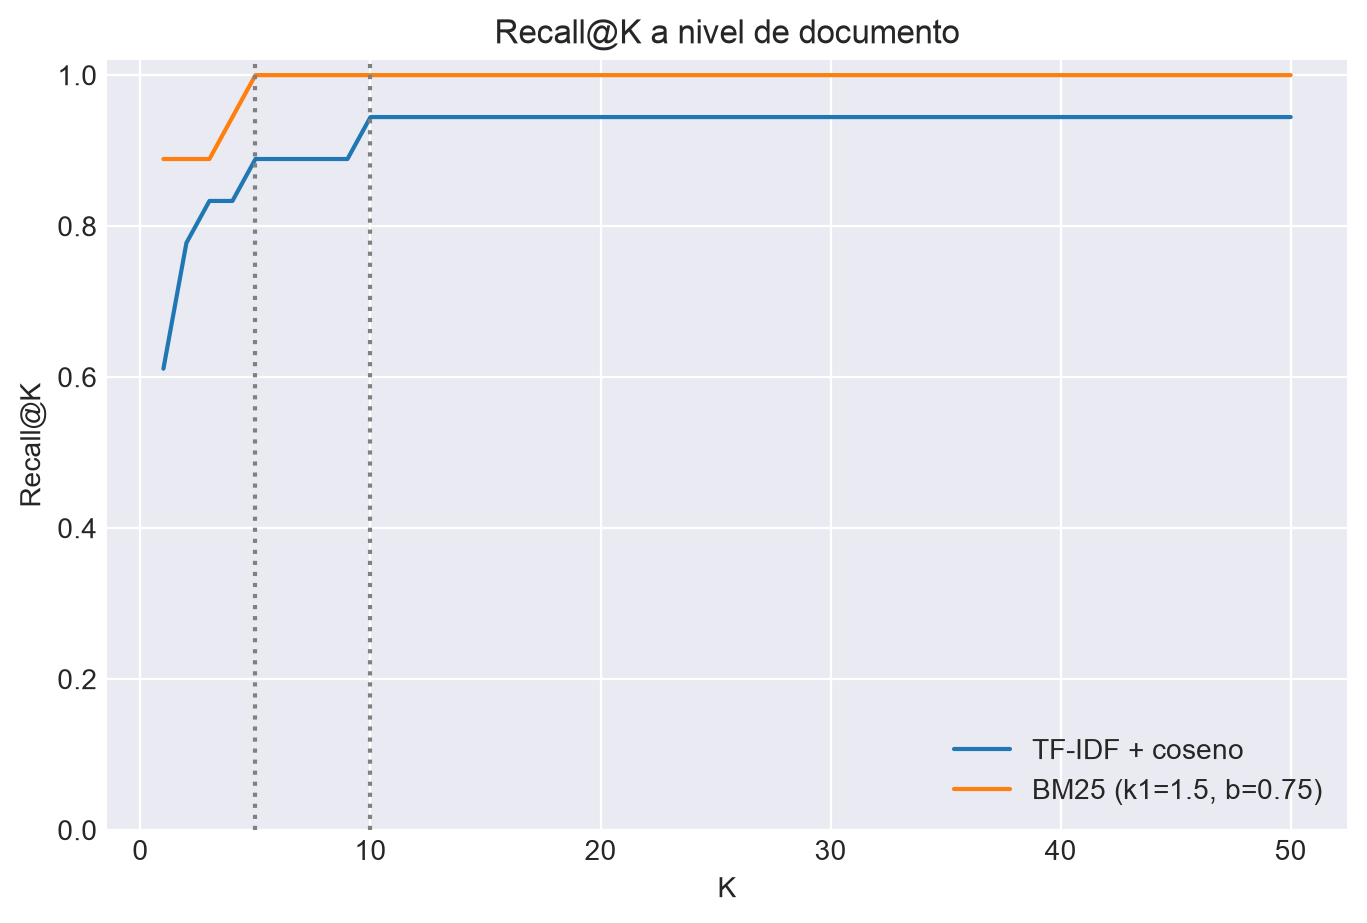

In [82]:
ks = range(1, 51)
for n in names:
    plt.plot(list(ks), [recall_at_k(doc_rankings[n], relevants, k) for k in ks], label=n)
plt.axvline(5, color='gray', ls=':'); plt.axvline(10, color='gray', ls=':')
plt.xlabel('K'); plt.ylabel('Recall@K'); plt.ylim(0, 1.02); plt.title('Recall@K a nivel de documento'); plt.legend()
plt.show()

## 5.3 · Sensibilidad de BM25

Probamos varias combinaciones de $k_1$ y $b$ para observar cuánto cambian los resultados.

- **$b=0$:** desactiva la normalización por longitud.
- **$b=1$:** aplica la normalización completa.
- **$k_1\to0$:** la contribución de frecuencia tiende a depender de la presencia del término.

> **Análisis exploratorio.** El baseline principal conserva $k_1=1.5$ y $b=0.75$. No seleccionamos la combinación con mejor resultado en el test. Si este análisis motiva ajustes, será necesario un conjunto de desarrollo y una evaluación final independiente.

In [83]:
rows = []
for k1 in (0.5, 1.2, 1.5, 2.0):
    for b_ in (0.0, 0.5, 0.75, 1.0):
        model = BM25(X_counts, k1=k1, b=b_)
        rankings = [top_docs(bm25_scores(t, model)) for t in query_tokens]
        rows.append({'k1': k1, 'b': b_, 'Recall@5': recall_at_k(rankings, relevants, 5),
                     'Recall@10': recall_at_k(rankings, relevants, 10), 'MRR@10': mrr(rankings, relevants, 10)})
grid = pd.DataFrame(rows)
display(grid.pivot(index='k1', columns='b', values='MRR@10').round(3).rename_axis(index='k1', columns='b  (MRR@10)'))
display(grid.pivot(index='k1', columns='b', values='Recall@10').round(3).rename_axis(index='k1', columns='b  (Recall@10)'))

b (MRR@10),0.00,0.50,0.75,1.00
k1,,,,
0.5,0.889,0.886,0.886,0.886
1.2,0.886,0.891,0.891,0.958
1.5,0.887,0.891,0.914,0.952
2.0,0.889,0.912,0.910,0.951


b (Recall@10),0.00,0.50,0.75,1.00
k1,,,,
0.5,0.944,1.0,1.0,1.0
1.2,1.000,1.0,1.0,1.0
1.5,1.000,1.0,1.0,1.0
2.0,1.000,1.0,1.0,1.0


---
# 6 · Análisis de errores
---

Inspeccionamos primero las consultas cuyo artículo queda fuera del top 10 con ambos métodos. También interesan aquellas en las que solo uno acierta.

Para cada caso, revisamos **la consulta, sus términos, la posición del artículo y los competidores recuperados**.

**Posibles causas**

| Causa | Qué comprobar |
|---|---|
| Desajuste de vocabulario | La consulta y el artículo expresan lo mismo con términos distintos |
| Evidencia no indexada | La información útil quedó fuera de los fragmentos seleccionados |
| Consulta genérica | Muchos artículos responden a una formulación demasiado amplia |
| Relevancia incompleta | Los competidores también son respuestas razonables |
| Pérdida por preprocesado | Se eliminaron términos necesarios para la búsqueda |

> **Lectura de los diagnósticos.** Un rango infinito significa que el artículo no aparece entre los cien resultados conservados. Las pistas automáticas no prueban una causa; el solape con el fragmento de origen tampoco describe todos los fragmentos del artículo.

In [84]:
chunk_tokens_by_id = dict(zip(chunks_df['chunk_id'], corpus))
def rank_in(ranking, doc_id):
    """Posición (1 = primero) del documento en el ranking; inf si no está entre los MAX_DEPTH primeros."""
    return ranking.index(doc_id) + 1 if doc_id in ranking else np.inf

rank_cols = {n: [rank_in(doc_rankings[n][i], q['relevant_ids'][0]) for i, q in enumerate(queries)] for n in names}

per_query = pd.DataFrame({'qid': [q['qid'] for q in queries], 'tema': q_topic,
                          'rango ' + short[a]: rank_cols[a], 'rango ' + short[b]: rank_cols[b]})
per_query['solape con el fragmento'] = [
    np.mean([t in set(chunk_tokens_by_id[q['source_chunk']]) for t in toks]) if toks else 0.0
    for q, toks in zip(queries, query_tokens)]

ra, rb = per_query['rango ' + short[a]], per_query['rango ' + short[b]]
both_fail = per_query[(ra > 10) & (rb > 10)]
only_one = per_query[((ra > 10) ^ (rb > 10))]
print(f'Fallan ambos métodos: {len(both_fail)} consultas · falla sólo uno: {len(only_one)} · aciertan ambos: {len(per_query) - len(both_fail) - len(only_one)}')

hit = (rb <= 10)
print('\nSolape medio de la consulta con su fragmento de origen:',
      f'consultas con acierto en BM25 = {per_query.loc[hit, "solape con el fragmento"].mean():.2f} · '
      f'con fallo = {per_query.loc[~hit, "solape con el fragmento"].mean():.2f}')

display(per_query.replace(np.inf, np.nan).round(2).sort_values('rango ' + short[b], ascending=False, na_position='first').head(10))

Fallan ambos métodos: 0 consultas · falla sólo uno: 1 · aciertan ambos: 17

Solape medio de la consulta con su fragmento de origen: consultas con acierto en BM25 = 0.55 · con fallo = nan


,qid,tema,rango TF-IDF,rango BM25,solape con el fragmento
11,q46,autonomous_vehicles,NaN,5,0.00
9,q32,reinforcement_learning,5.0,4,0.46
1,q03,deep_learning,1.0,1,0.38
16,q57,neural_networks,10.0,1,0.18
15,q56,neural_networks,1.0,1,0.43
14,q53,autonomous_vehicles,2.0,1,0.11
13,q52,reinforcement_learning,1.0,1,0.85
12,q50,nlp,1.0,1,1.00
10,q40,reinforcement_learning,1.0,1,0.64
0,q02,deep_learning,1.0,1,0.70


In [85]:
def hint(i):
    toks = query_tokens[i]
    in_vocab = [t for t in toks if t in D.token2id]
    src = set(chunk_tokens_by_id[queries[i]['source_chunk']])
    missing = [t for t in set(toks) if t not in src]
    if not in_vocab:
        return 'ningún término de la consulta está en el vocabulario', missing
    if toks and len(missing) / len(set(toks)) >= 0.5:
        return 'vocabulary mismatch: la mitad o más de los términos de la consulta no aparecen en el fragmento de origen', missing
    return 'los términos aparecen, pero otros papers los usan con más peso (consulta poco discriminativa o competidores razonables)', missing

for i in both_fail.index:
    q, doc = queries[i], docs_by_id[queries[i]['relevant_ids'][0]]
    pista, missing = hint(i)
    print('=' * 120)
    print(f'[{q["qid"]}] tema: {q_topic[i]}')
    print('CONSULTA  :', q['query'])
    print('TÉRMINOS  :', query_tokens[i])
    print('RELEVANTE :', doc['title'][:100])
    print(f'RANGO     : {short[a]} = {ra[i]}, {short[b]} = {rb[i]}')
    print('TÉRMINOS AUSENTES DEL FRAGMENTO DE ORIGEN:', sorted(missing))
    print('PISTA     :', pista)
    for n in names:
        print(f'  top-3 {short[n]}:', ' | '.join(f'{docs_by_id[d]["title"][:55]} ({docs_by_id[d]["topic"]})' for d in top_docs(S[n][i], 3)))
if both_fail.empty:
    print('Ninguna consulta falla con ambos métodos. Mirad igualmente las que fallan con uno solo (tabla anterior).')

Ninguna consulta falla con ambos métodos. Mirad igualmente las que fallan con uno solo (tabla anterior).


## 6.1 · Alcance de la evaluación

Las métricas y los diagnósticos por consulta permiten comparar los métodos y examinar sus diferencias entre áreas. La atribución de una causa concreta requiere contrastar la consulta con el artículo de origen y sus competidores.

La generación exige términos compartidos y puede favorecer la recuperación léxica. Además, generador y juez utilizan por defecto el mismo modelo, por lo que sus valoraciones no constituyen una validación independiente.

---
# 7 · Síntesis del experimento
---

Las celdas siguientes comprueban los requisitos cuantitativos y exportan una síntesis de la configuración y las métricas a `MILESTONE_1_draft.md`.

La reproducción del experimento requiere conservar el corpus y las consultas, además de registrar parámetros, modelos y versiones del entorno.

El constructor y los pasos costosos reutilizan archivos existentes. Los cambios en datos o configuración pueden requerir regenerar las cachés y, si se sustituyen las consultas candidatas, repetir su revisión.

In [86]:
status = [
    ('Corpus de miles de papers', len(docs_df) >= 1000, f'{len(docs_df)} papers, {docs_df["topic"].nunique()} temas'),
    ('Fragmentos de 200-400 palabras con solape del 10-20 %', 200 <= CHUNK_WORDS <= 400 and 0.10 <= CHUNK_OVERLAP <= 0.20,
     f'{CHUNK_WORDS} palabras, {CHUNK_OVERLAP:.0%} de solape, {len(chunks_df)} fragmentos indexados'),
    ('Cada fragmento con id propio y el de su documento', bool(chunks_df['chunk_id'].is_unique and chunks_df['doc_id'].notna().all()), ''),
    (f'Al menos {N_QUERIES_MIN} consultas known-item', len(queries) >= N_QUERIES_MIN, f'{len(queries)} consultas en queries.jsonl'),
    (f'Al menos {MIN_REVIEWED} consultas revisadas a mano y documentadas', len(REVIEW) >= MIN_REVIEWED, f'{len(REVIEW)} en REVIEW -> {os.path.basename(REVIEW_FILE)}'),
    ('Consultas de los 5 temas', all(Counter(q_topic).get(t, 0) > 0 for t in TOPICS), str(dict(Counter(q_topic)))),
    ('TF-IDF + coseno y BM25 evaluados (Recall@5, Recall@10, MRR)', True, bm25_label),
]
for name, ok, detail in status:
    print(('[cumple]' if ok else '[no cumple]'), name, '·', detail)

[hecho]     Corpus de miles de papers · 4000 papers, 5 temas
[hecho]     Fragmentos de 200-400 palabras con solape del 10-20 % · 300 palabras, 15% de solape, 10000 fragmentos indexados
[hecho]     Cada fragmento con id propio y el de su documento · 
[falta]     Al menos 30 consultas known-item · 18 consultas en queries.jsonl
[falta]     Al menos 10 consultas revisadas a mano y documentadas · 0 en REVIEW -> queries_review.csv
[hecho]     Consultas de los 5 temas · {'deep_learning': 2, 'neural_networks': 5, 'autonomous_vehicles': 3, 'reinforcement_learning': 4, 'nlp': 4}
[hecho]     TF-IDF + coseno y BM25 evaluados (Recall@5, Recall@10, MRR) · BM25 (k1=1.5, b=0.75)
[pendiente] Análisis de fallos escrito en la sección 6 · manual: completad la celda de análisis
[pendiente] Declaración de uso de herramientas de IA en MILESTONE_1.md · manual


In [87]:
def md_table(df):
    cols = list(df.columns)
    lines = ['| Método | ' + ' | '.join(cols) + ' |', '|---|' + '---|' * len(cols)]
    lines += [f'| {name} | ' + ' | '.join(f'{v:.3f}' for v in row) + ' |' for name, row in df.iterrows()]
    return '\n'.join(lines)

draft = f"""# Hito 1 — Baseline de recuperación

## Qué se ha hecho
- **Corpus**: {len(docs_df)} papers de arXiv ({DATE_START} a {DATE_END}), {PAPERS_PER_TOPIC} por tema: {', '.join(TOPICS)}. Metadatos con la API de arXiv y PDFs del bucket público `gs://arxiv-dataset`.
- **Unidad de indexación**: fragmentos de {CHUNK_WORDS} palabras con solape del {CHUNK_OVERLAP:.0%}; se indexan {len(chunks_df)} fragmentos ({len(chunks_df) / len(docs_df):.1f} por paper de media: siempre el primero, con título y resumen, y el resto repartido por el texto).
- **Preprocesado**: spaCy `en_core_web_sm` (lemas de {', '.join(sorted(VALID_POS))}, sin stopwords), n-gramas con Gensim `Phrases`, términos en ≥ {NO_BELOW} fragmentos y en ≤ {NO_ABOVE:.0%}. Vocabulario final: {len(D)} términos.
- **Consultas**: {len(queries)} consultas known-item generadas con `{LLM_MODEL}` a partir de título + resumen + fragmento, con controles automáticos de coherencia (alineación con el resumen, no copia, juicio del LLM) y {len(REVIEW)} revisadas a mano (`queries_review.csv`).
- **Baselines**: TF-IDF + coseno (Gensim, tf bruta × log2(N/df), norma L2) y BM25 propio (Okapi, IDF de Lucene, k1={BM25_K1}, b={BM25_B}, estadísticas sobre fragmentos).

## Resultados (nivel documento, {len(queries)} consultas)
{md_table(results_df[['Recall@5', 'Recall@10', 'MRR@10']])}

(Intervalos de confianza y desglose por tema en el notebook.)

## Alcance
- La evaluación considera relevante el artículo de origen de cada consulta; no incluye juicios exhaustivos sobre los demás resultados.
- El índice conserva una selección de fragmentos por artículo, lo que limita la evidencia disponible para la recuperación.

## Siguiente paso
- Hito 2: recuperación densa con embeddings y base de datos vectorial sobre los mismos fragmentos, comparada con estos baselines en las mismas consultas.

## Uso de herramientas de IA generativa
- `{LLM_MODEL}` (servidor de la UC3M): generación de las consultas de prueba y puntuación de su coherencia.
- Asistencia de IA para revisar la redacción, la presentación y los comentarios del notebook y de `corpus_builder.py`.
"""
draft_path = os.path.join(OUT_DIR, 'MILESTONE_1_draft.md')
with open(draft_path, 'w', encoding='utf-8') as f:
    f.write(draft)
print('Síntesis guardada en', draft_path)

Borrador guardado en ./MILESTONE_1_draft.md -> copiadlo a MILESTONE_1.md, completadlo (una página) y entregadlo en Aula Global con el commit.
